# 2. Your own signature

A signature can be:
- a gene list (up genes only);
- a dict `{"up": [...], "down": [...]}`;
- a CSV/TSV with `gene` and `direction` columns (up/down, +/−, 1/−1), or with side-by-side `up` and `down` columns;
- a `.gmt` file (pairs named `X_UP` / `X_DOWN` are merged);
- a signature you register with `al.sig.register`, which then works like a built-in one.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import anchorline as al

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 60)
al.settings.figdir = "figures"          # save=True writes here
al.settings.set_figure_params(fontsize=8.5, dpi=150)
atlas = al.load()                       # first time: downloads the atlas (~560 MB) to al.settings.data_dir
atlas

loading atlas from /Users/sina.kanannejad/.anchorline/data (~1-2 min, ~1.5 GB RAM)
  8894 reference samples (2805 untreated), 42003 genes; 1608 drug-vs-control contrasts


anchorline Atlas (/Users/sina.kanannejad/.anchorline/data)
  reference: 8894 samples (2805 untreated) x 42003 genes
  contrasts: 1608 (226 studies, 63 models, 363 drugs)

## A gene list

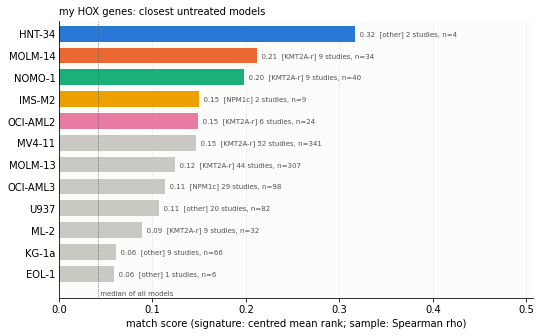

In [2]:
mt = al.tl.match(atlas, ["HOXA9", "HOXA10", "MEIS1", "PBX3", "MEF2C"], name="my HOX genes")
al.pl.match_ranking(mt, n_top=12)

## Up and down genes

In [3]:
stem = {"up": ["CD34", "HLF", "MECOM", "PROM1", "SPINK2", "CRHBP", "GATA2", "MEIS1"],
        "down": ["MPO", "ELANE", "LYZ", "CD14", "S100A8", "S100A9", "CEBPE", "ITGAM"]}
mt = al.tl.match(atlas, stem, name="stem vs myeloid")
mt.info                                   # how many genes were found in the atlas

{'n_up_used': 8, 'n_down_used': 8, 'n_up_given': 8, 'n_down_given': 8}

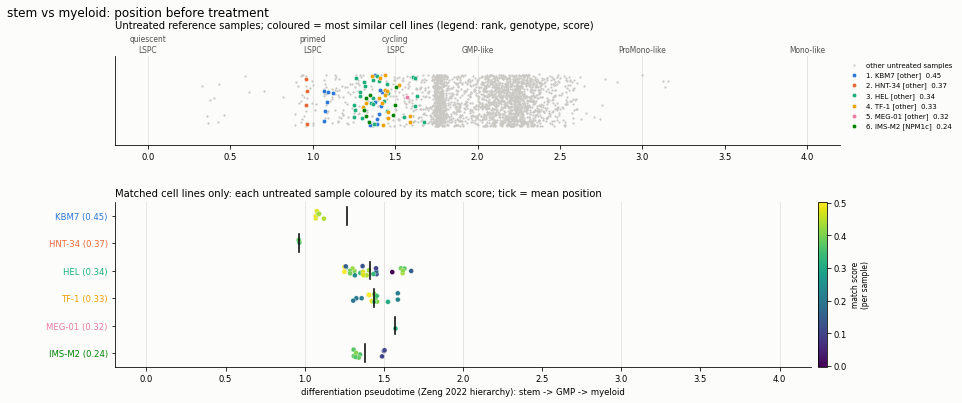

In [4]:
al.pl.pseudotime(mt, n_top=6)

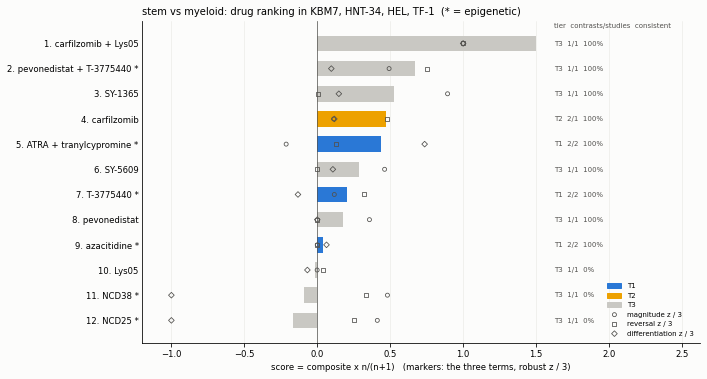

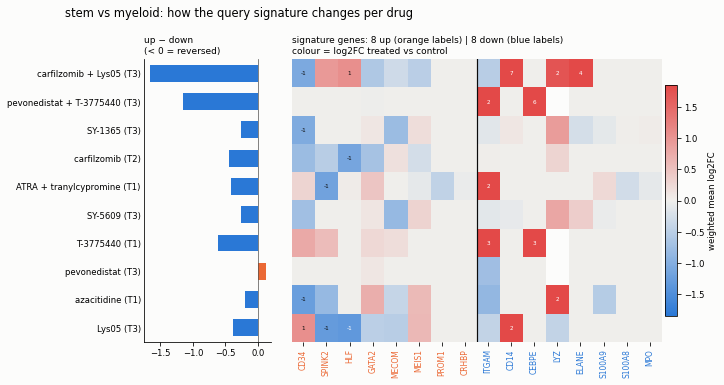

In [5]:
dr = al.tl.rank_drugs(atlas, mt, cell_lines=4)
al.pl.drug_ranking(dr, n_top=12)
al.pl.signature_changes(dr, n_top=10)

## From a CSV file

In [6]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
pd.DataFrame({"gene": stem["up"] + stem["down"],
              "direction": ["up"] * len(stem["up"]) + ["down"] * len(stem["down"])}).to_csv("figures/my_signature.csv", index=False)
q = al.io.read_query("figures/my_signature.csv")        # read_query shows what was understood
q

Query('my_signature', signature: 8 up, 8 down)

In [7]:
mt_csv = al.tl.match(atlas, "figures/my_signature.csv")
(mt_csv.table.index[:5] == mt.table.index[:5]).all()     # same result as the dict

True

## Register it, then use it like a built-in signature

In [8]:
al.sig.register("my_stem_vs_myeloid", up=stem["up"], down=stem["down"], description="toy stem-vs-myeloid set")
al.sig.list("my_")

,collection,n_up,n_down,description,source,doi
name,,,,,,
my_stem_vs_myeloid,user,8,8,toy stem-vs-myeloid set,,


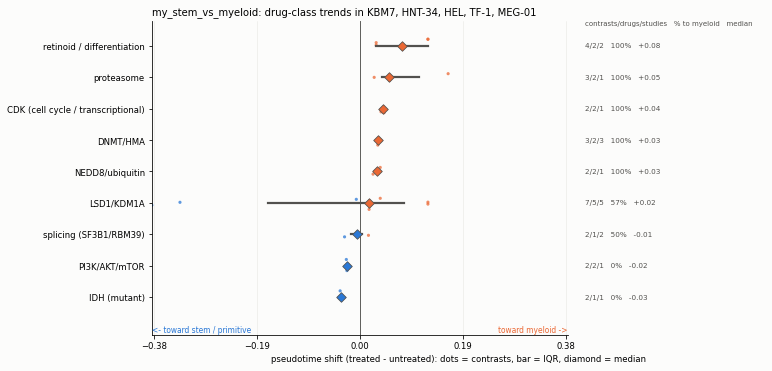

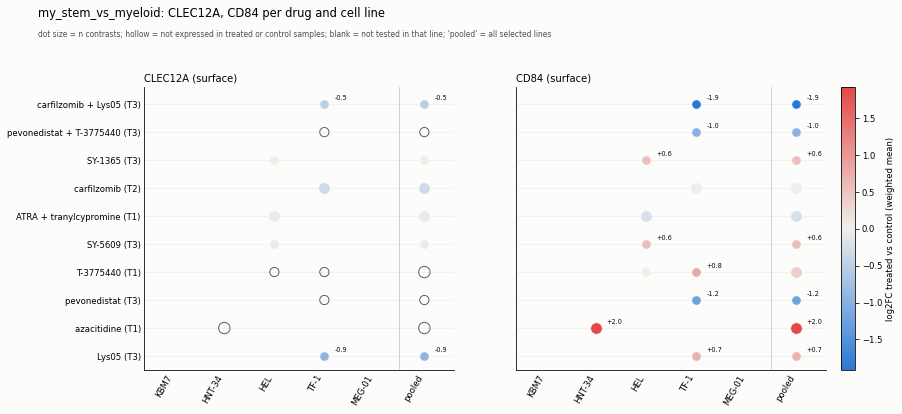

In [9]:
mt = al.tl.match(atlas, "my_stem_vs_myeloid")
dr = al.tl.rank_drugs(atlas, mt, cell_lines=5)
al.pl.class_trends(dr, n_top=10)
al.pl.gene_changes(dr, genes=["CLEC12A", "CD84"], n_top=10)

## A .gmt file

In [10]:
gmt = Path("figures/my_sets.gmt")
gmt.write_text("MYSET_UP\tdemo\t" + "\t".join(stem["up"]) + "\nMYSET_DOWN\tdemo\t" + "\t".join(stem["down"]) + "\n")
sets = al.sig.read_gmt(gmt)               # MYSET_UP + MYSET_DOWN -> one signature "MYSET"
sets

{'MYSET': Signature('MYSET': 8 up, 8 down)}

## Including PDX and primary models
`models="all"` lets PDX and primary samples match too. Their drug lists are short, though: most have only 1–5 drug comparisons.

In [11]:
mt_all = al.tl.match(atlas, "Umeda2024_KMT2Ar_high", models="all")
mt_all.table.head(8)[["score", "studies", "genotype", "is_cell_line"]]

,score,studies,genotype,is_cell_line
cell_line,,,,
MOLM-13 (plus murine ER-Hoxa9),0.151561,1,unknown,False
OCI-AML2,0.129570,6,KMT2A-r,True
pediatric AML PDX (8 models),0.118555,1,unknown,False
NOMO-1,0.112956,9,KMT2A-r,True
MOLM-13,0.106263,44,KMT2A-r,True
MLL-r AML PDX cells (AML-18),0.102462,1,unknown,False
MOLM-14,0.087806,9,KMT2A-r,True
1 leukaemia patient (CCS1477 trial),0.082661,1,unknown,False
